# EDA del balance de entradas y salidas de MiBici — 2023

Este notebook documenta la versión con fechas explícitas: ISO (`año-mes-día`) y fechas con barras (`día/mes/año`, utilizadas en noviembre). Analiza los viajes conservados por el flujo oficial de limpieza. Cada fila del Parquet horario representa una estación y una hora; el balance es **entradas − salidas**.

La lógica está en `mibici/plots.py`, reutilizable desde terminal o notebook. Se generan estadísticas, seis gráficas e interpretaciones y se registran en MLflow. El alcance es descriptivo: no se entrena un modelo ni se infiere disponibilidad real de bicicletas.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from mibici.plots import run_eda

resultado = run_eda(
    input_path=ROOT / 'data/interim/hourly_balance_2023.parquet',
    features_path=ROOT / 'data/processed/features_2023.parquet',
    figures_dir=ROOT / 'reports/figures',
    report_dir=ROOT / 'reports/eda',
    station_id=51,
)
tablas = json.loads(Path(resultado['tablas']).read_text())
print('MLflow run_id:', resultado['run_id'])
print('Los hashes de los dos Parquet se registraron con esta ejecución.')

/Users/villegas/Documents/Codex/Maestria/MLOps/Proyecto/ML_pipeline_eq6/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/10/25 14:09:54 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /Users/villegas/Documents/Codex/Maestria/MLOps/Proyecto/ML_pipeline_eq6/.venv/lib/python3.14/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


2026-10-25 14:09:55.403 | INFO     | mibici.config:<module>:12 - PROJ_ROOT path is: /Users/villegas/Documents/Codex/Maestria/MLOps/Proyecto/ML_pipeline_eq6


2026-10-25 14:09:55.911 | INFO     | mibici.tracking:data_run:63 - MLflow run_id (plots): 2f70489852114915b5c5054611733e78


/Users/villegas/Documents/Codex/Maestria/MLOps/Proyecto/ML_pipeline_eq6/.venv/lib/python3.14/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dataset source can be interpreted in multiple ways: LocalArtifactDatasetSource, LocalArtifactDatasetSource. MLflow will assume that this is a LocalArtifactDatasetSource source.
  return _dataset_source_registry.resolve(


/Users/villegas/Documents/Codex/Maestria/MLOps/Proyecto/ML_pipeline_eq6/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
/Users/villegas/Documents/Codex/Maestria/MLOps/Proyecto/ML_pipeline_eq6/.venv/lib/python3.14/site-packages/mlflow/data/dataset_source_registry.py:148: UserWarning: The specified dat

/Users/villegas/Documents/Codex/Maestria/MLOps/Proyecto/ML_pipeline_eq6/.venv/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run plots at: http://127.0.0.1:5001/#/experiments/1/runs/2f70489852114915b5c5054611733e78
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
2026-10-25 14:10:32.285 | SUCCESS  | mibici.plots:run_eda:379 - EDA terminado: 2f70489852114915b5c5054611733e78
MLflow run_id: 2f70489852114915b5c5054611733e78
Los hashes de los dos Parquet se registraron con esta ejecución.


## 1. Volumen, distribución y significado de los ceros

Se comprueban totales y dimensiones. Las entradas y salidas globales coinciden porque se conservan solo viajes con inicio y fin dentro del año. **Balance cero** puede indicar igual número de llegadas y salidas con movimientos; **entradas y salidas simultáneamente cero** significa que no hay movimientos registrados. Los ceros no identifican cierres ni disponibilidad de una estación.

In [2]:
display(pd.DataFrame.from_dict(resultado['metricas'], orient='index', columns=['valor']))
display(pd.DataFrame(tablas['estadisticas']))

,valor
filas_hourly,3.144840e+06
columnas_hourly,5.000000e+00
filas_features,3.084528e+06
columnas_features,3.300000e+01
estaciones,3.590000e+02
dias_observados,3.650000e+02
entradas_total,4.275165e+06
salidas_total,4.275165e+06
porcentaje_sin_movimientos,4.854241e+01
porcentaje_balance_cero_con_movimientos,8.853710e+00


,variable,count,mean,std,min,25%,50%,75%,max
0,entradas,3144840.0,1.359422,2.697186,0.0,0.0,0.0,2.0,109.0
1,salidas,3144840.0,1.359422,2.573077,0.0,0.0,0.0,2.0,91.0
2,balance,3144840.0,0.000000,1.923857,-76.0,0.0,0.0,0.0,83.0


## 2. Patrones horarios y días de la semana

Se comparan entradas y salidas de lunes a viernes frente al fin de semana. Las horas pico se observan en las curvas, sin fijarlas como resultado previo. Para comparar días de la semana se usa el **promedio de viajes por día**, evitando el efecto de que un día aparezca 52 o 53 veces en el año.

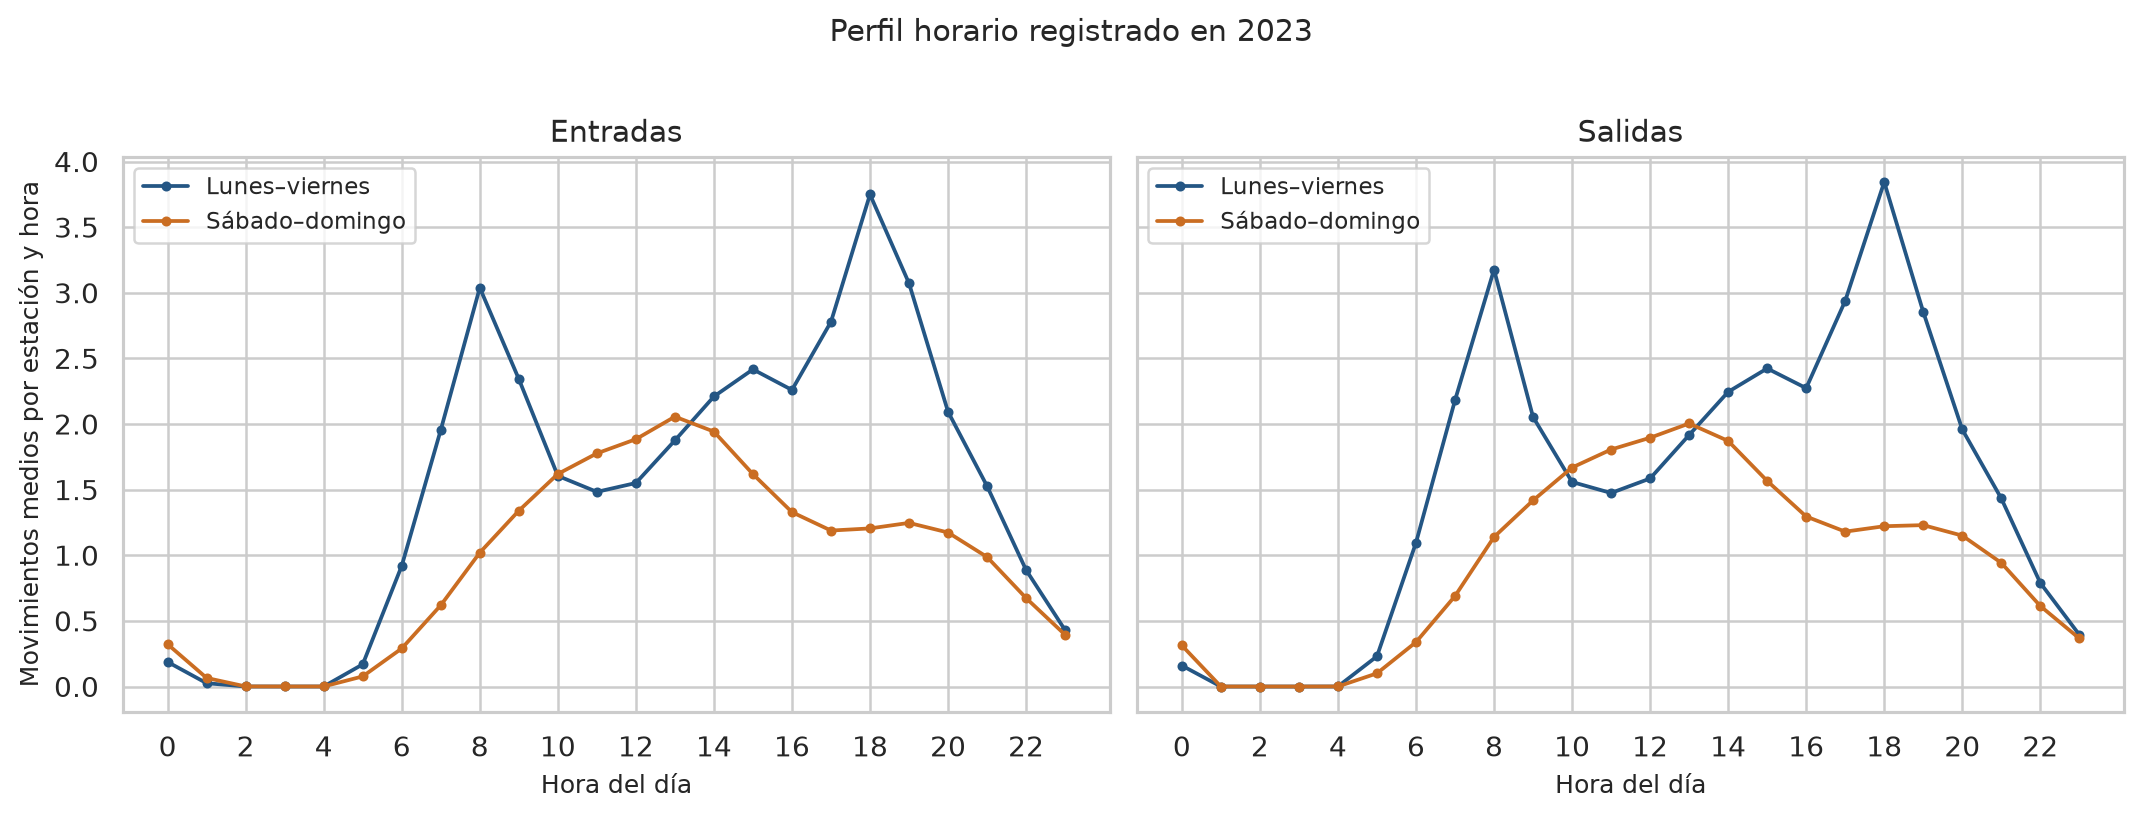

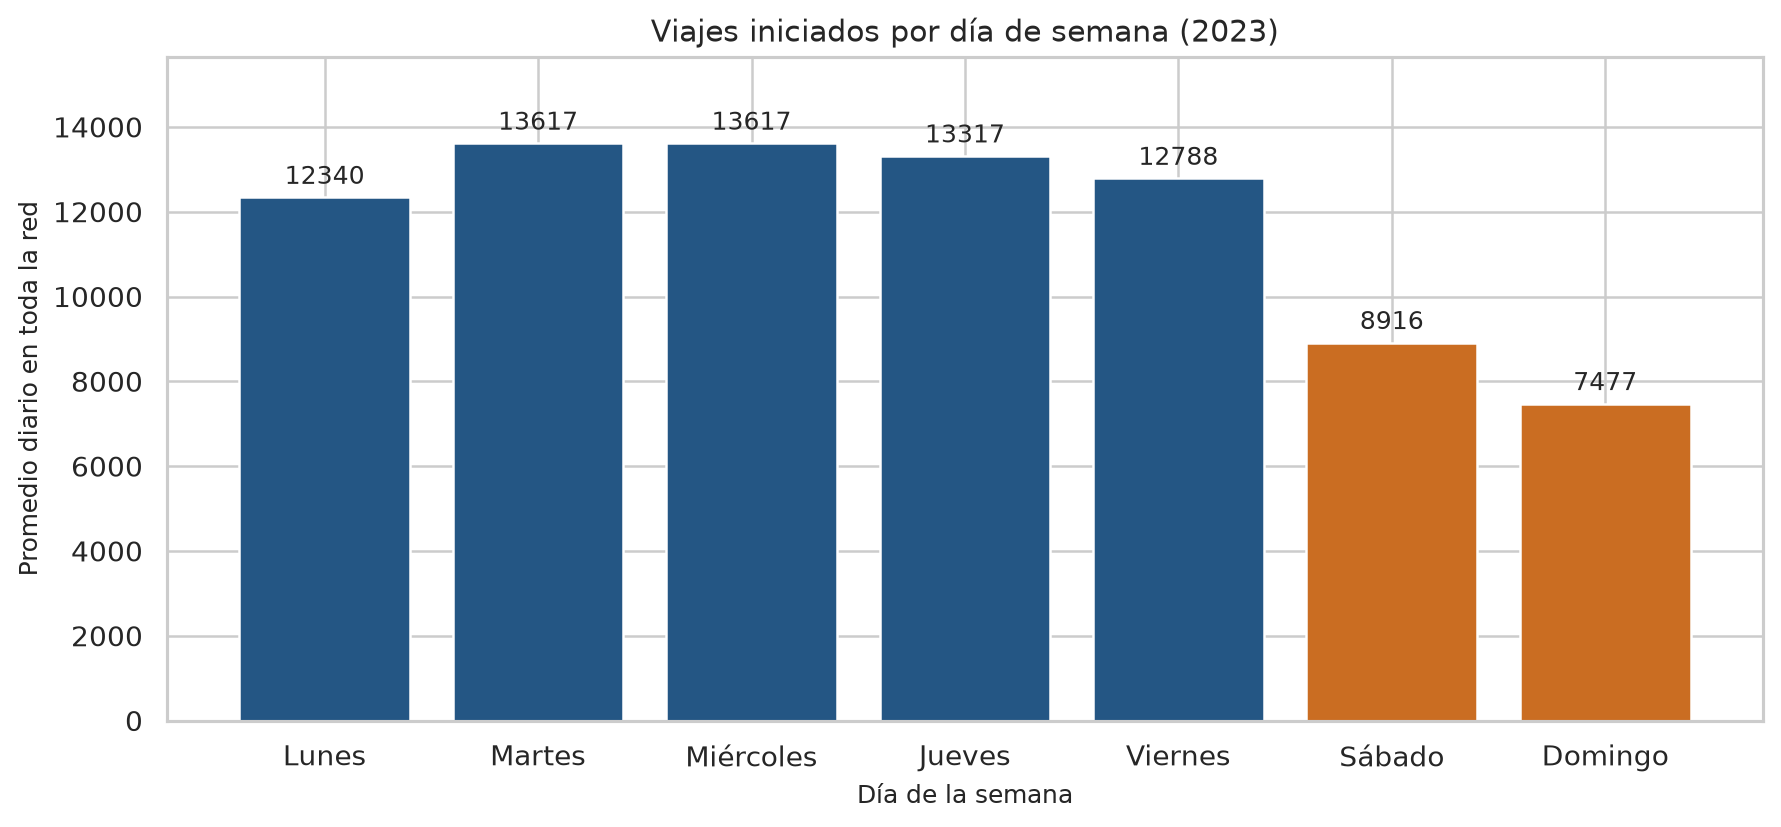

,dia_semana,entradas_total,salidas_total,entradas_media_diaria,salidas_media_diaria,dias_observados,nombre_dia
0,0,641531,641661,12337.134615,12339.634615,52,Lunes
1,1,707855,708080,13612.596154,13616.923077,52,Martes
2,2,708019,708081,13615.750000,13616.942308,52,Miércoles
3,3,692342,692468,13314.269231,13316.692308,52,Jueves
4,4,664797,664995,12784.557692,12788.365385,52,Viernes
5,5,463653,463614,8916.403846,8915.653846,52,Sábado
6,6,396968,396266,7489.962264,7476.716981,53,Domingo


In [3]:
display(Image(filename=str(ROOT / 'reports/figures/01_flujo_horario_pico.png')))
display(Image(filename=str(ROOT / 'reports/figures/02_demanda_dia_semana.png')))
display(pd.DataFrame(tablas['dias_semana']))

## 3. Cambios entre meses

Se compara el promedio diario de viajes iniciados por mes para considerar su distinta duración. Los CSV se validan contra el mes de sus inicios de viaje. Las diferencias observadas no permiten atribuir causas como clima, cambios de oferta o cierres sin datos adicionales.

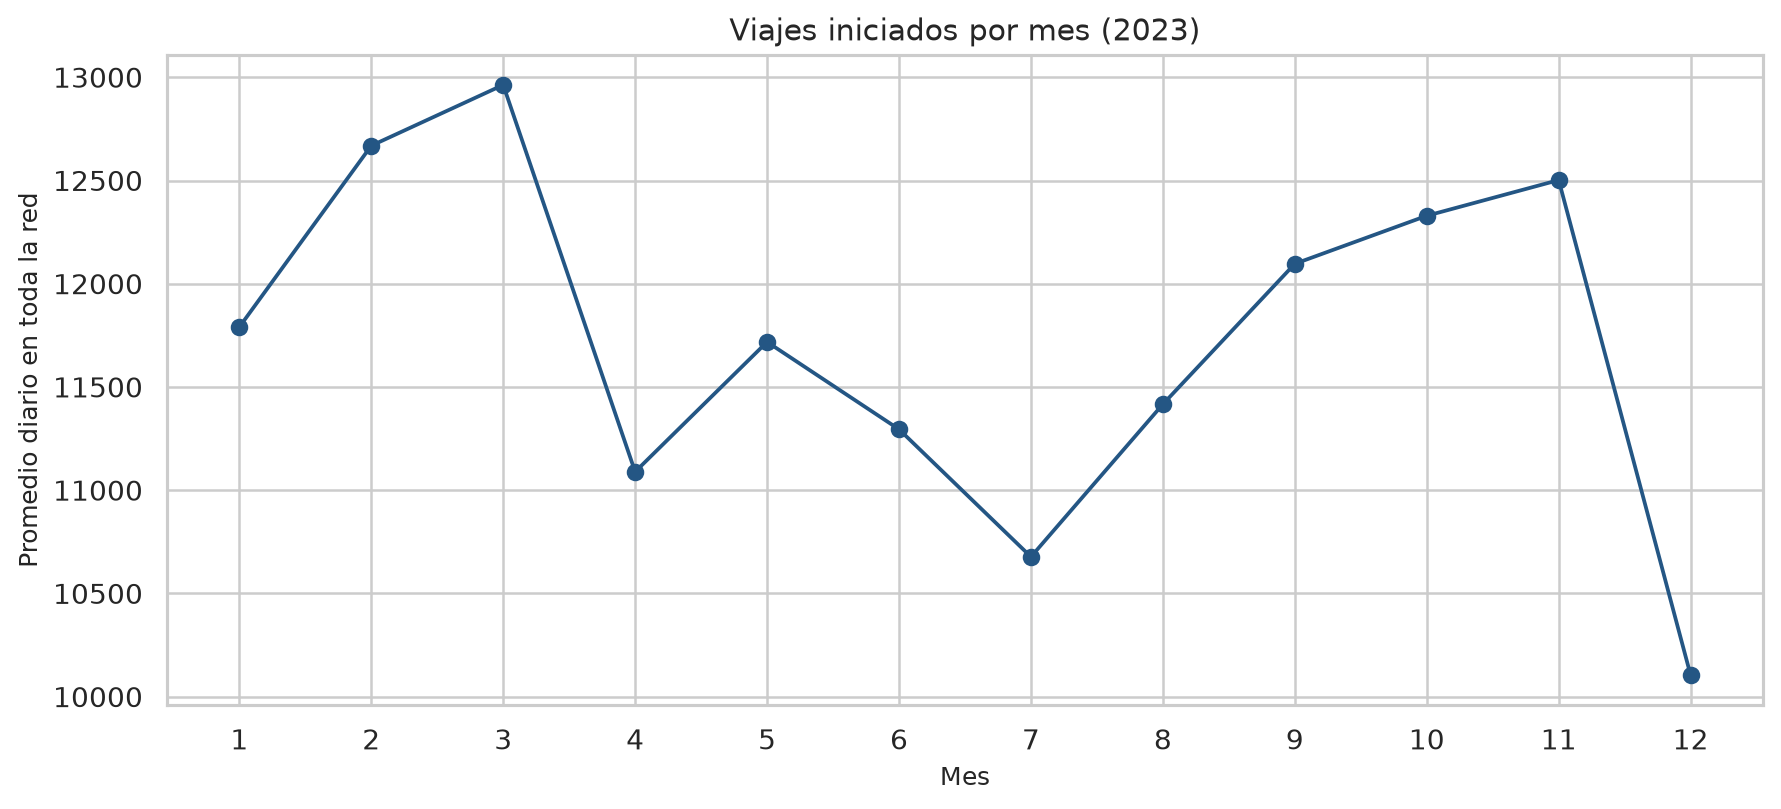

,mes,entradas_total,salidas_total,salidas_media_diaria,dias_observados
0,1,365475,365497,11790.225806,31
1,2,354719,354718,12668.500000,28
2,3,401840,401853,12963.000000,31
3,4,332694,332679,11089.300000,30
4,5,363254,363262,11718.129032,31
5,6,338850,338850,11295.000000,30
6,7,331005,331002,10677.483871,31
7,8,353918,353912,11416.516129,31
8,9,362897,362900,12096.666667,30
9,10,382211,382207,12329.258065,31


In [4]:
display(Image(filename=str(ROOT / 'reports/figures/06_flujo_mensual.png')))
display(pd.DataFrame(tablas['meses']))

## 4. Desbalance por estación

El ranking suma **|entradas − salidas| de cada hora**. Es distinto del balance neto acumulado: los desbalances positivos y negativos no se cancelan. El indicador también depende del volumen de uso y sirve para priorizar análisis; no demuestra urgencia de rebalanceo ni falta de bicicletas.

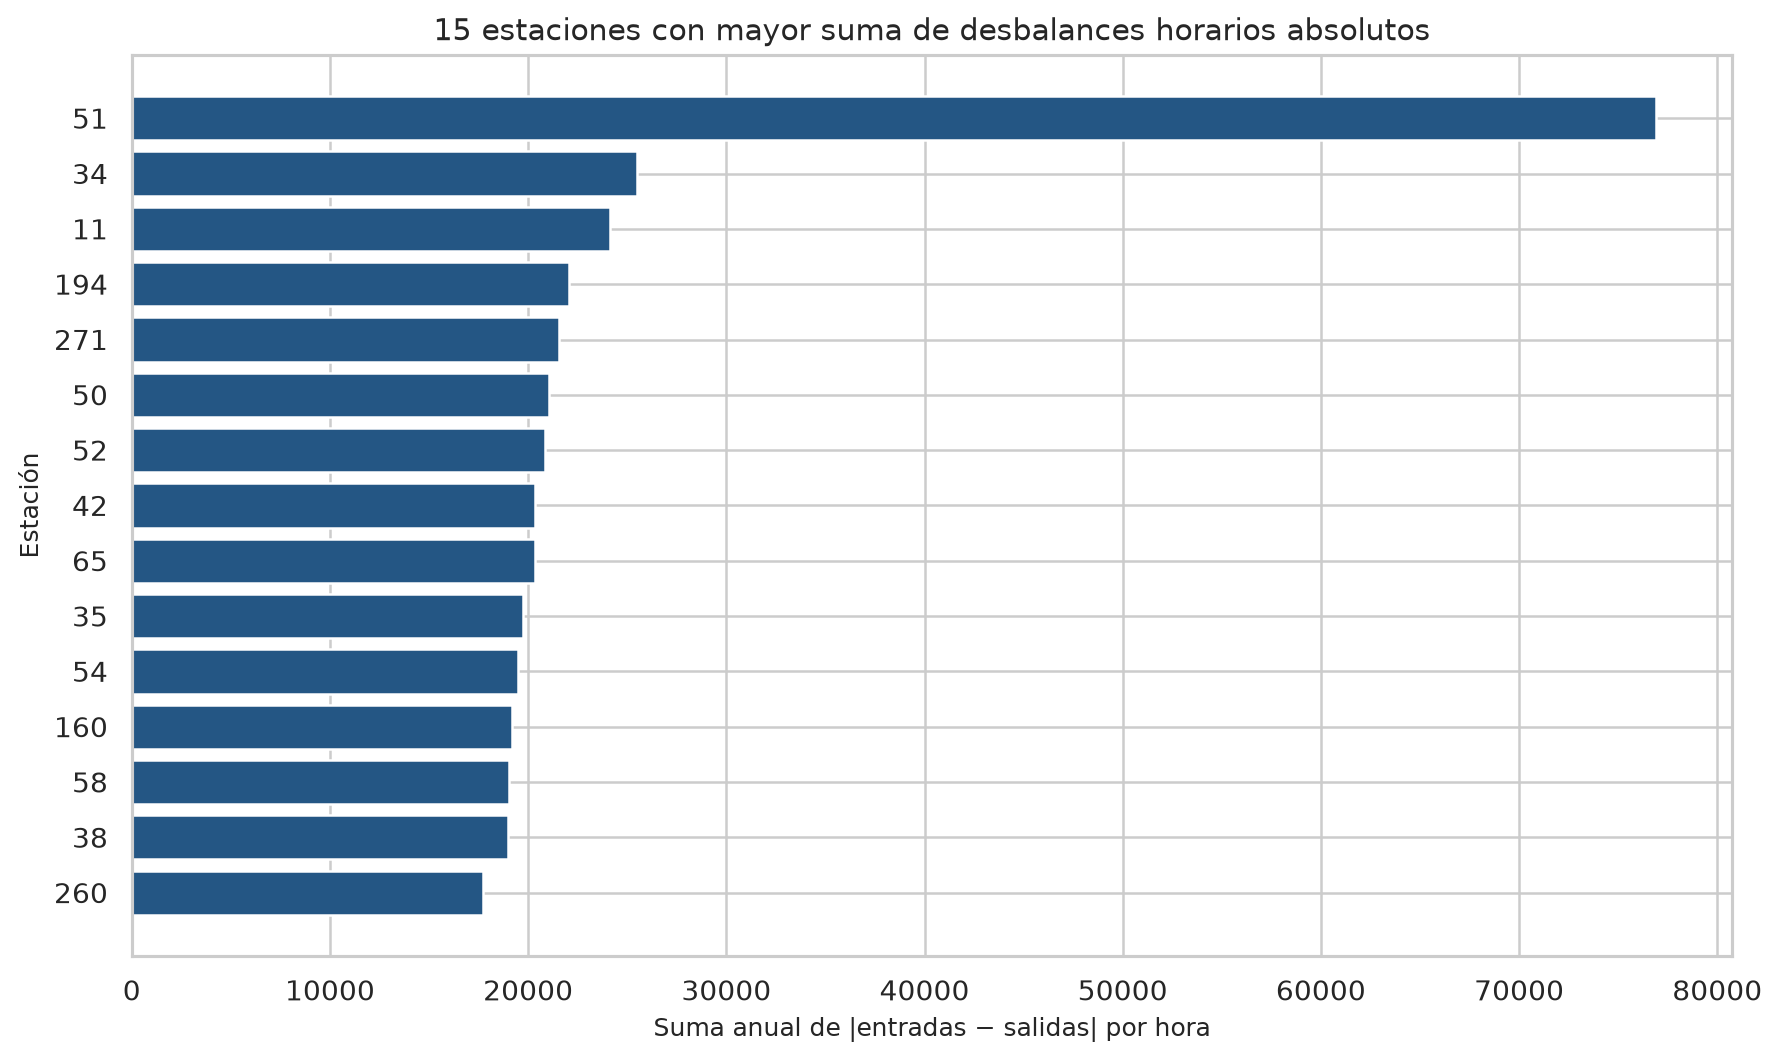

,estacion_id,total_entradas,total_salidas,balance_neto,desbalance_absoluto
0,51,116081,95333,20748,76910
1,34,52276,36622,15654,25482
2,11,62597,66958,-4361,24111
3,194,26827,40931,-14104,22064
4,271,64059,66520,-2461,21553
5,50,59813,57317,2496,21074
6,52,61042,60434,608,20830
7,42,27856,21079,6777,20355
8,65,30671,33674,-3003,20337
9,35,72513,63364,9149,19725


In [5]:
display(Image(filename=str(ROOT / 'reports/figures/03_top_estaciones_desbalance.png')))
display(pd.DataFrame(tablas['estaciones']).head(15))

## 5. Caso ilustrativo: estación 51

Se muestra su perfil medio de lunes a viernes. Un balance positivo representa más llegadas que salidas en esa hora y uno negativo, más salidas que llegadas. La estación 51 se mantiene para comparar con el análisis inicial del equipo; la gráfica no describe inventario acumulado.

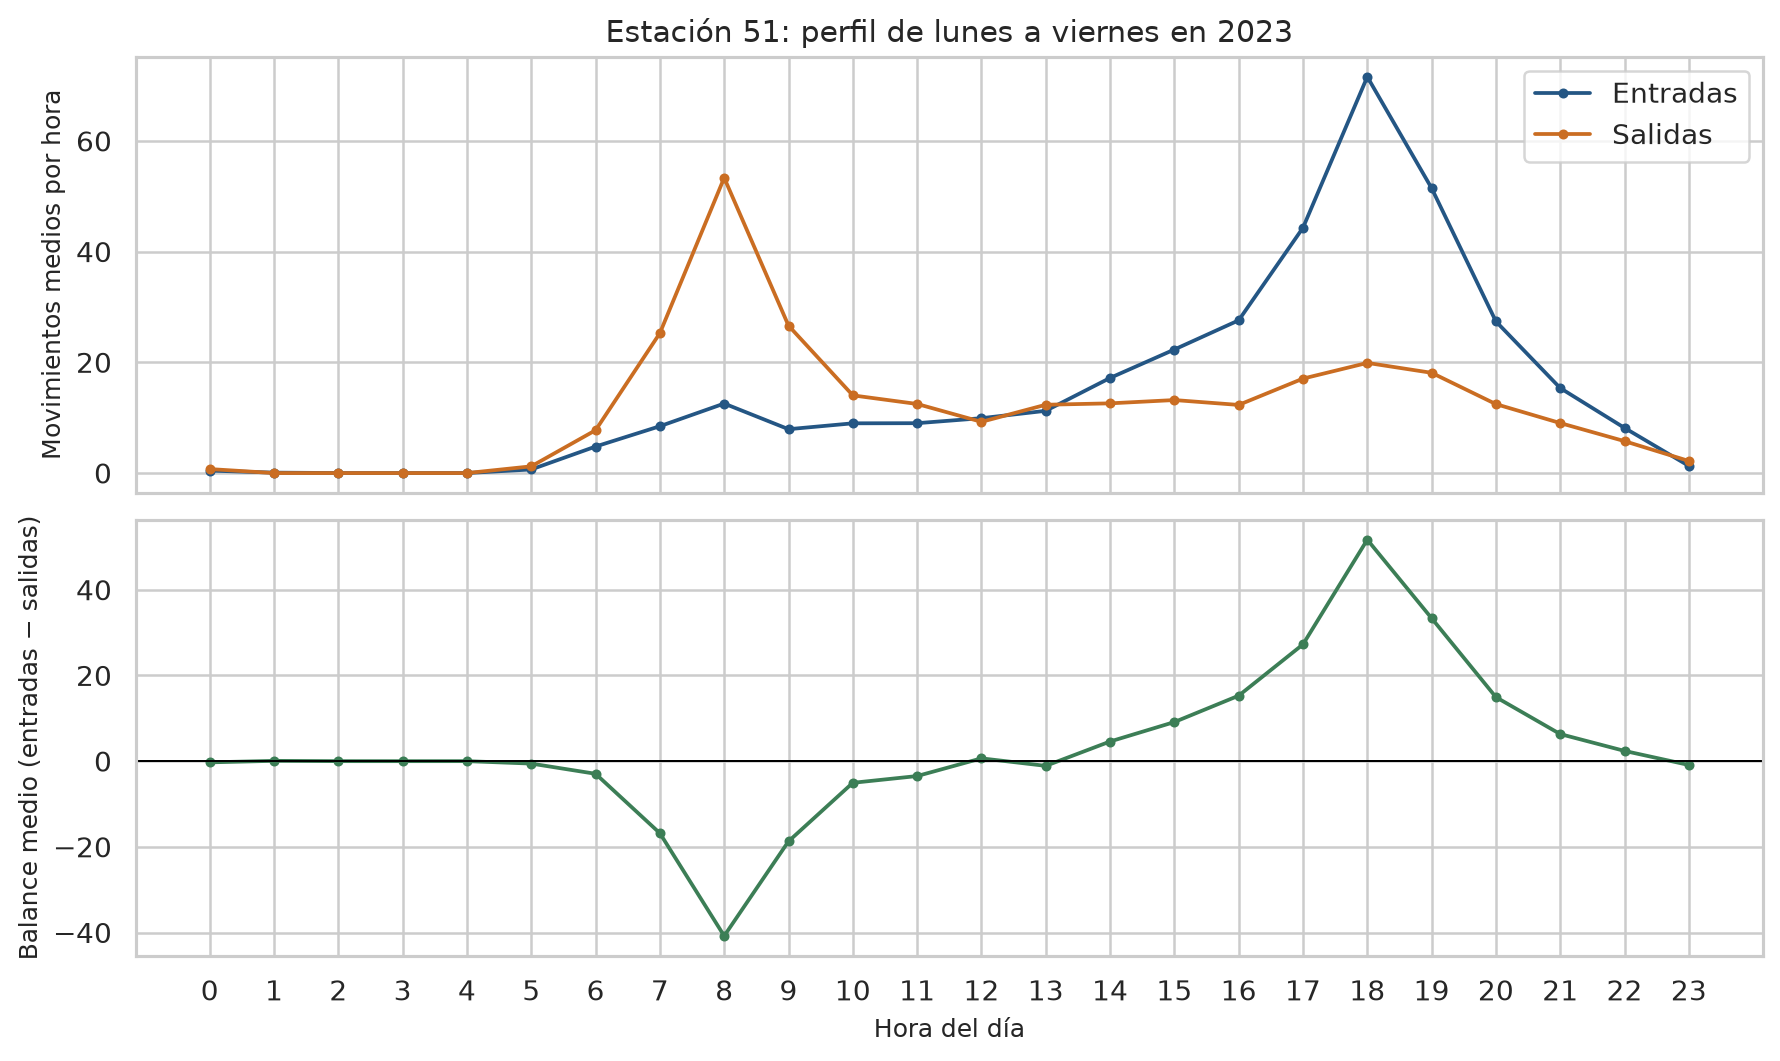

In [6]:
display(Image(filename=str(ROOT / 'reports/figures/04_dinamica_estacion_51.png')))

## 6. Variables históricas y correlaciones

Las correlaciones se calculan **solo con enero–septiembre**, el tramo de entrenamiento previsto, e incluyen los retardos de 1, 24 y 168 horas y las medias móviles de las 6 horas anteriores. Las medias se calculan por estación, excluyendo la hora actual. La correlación no prueba causalidad ni precisión predictiva; la relación entre balance, entradas y salidas también depende de la definición del balance.

Se conserva la codificación cíclica de hora y día de la semana. No se aplican escalado ni PCA: el modelo de árboles existente no requiere escalado y se prioriza interpretar las variables. El identificador numérico de estación y la bandera de hora pico son decisiones provisionales que deberán evaluarse en modelado.

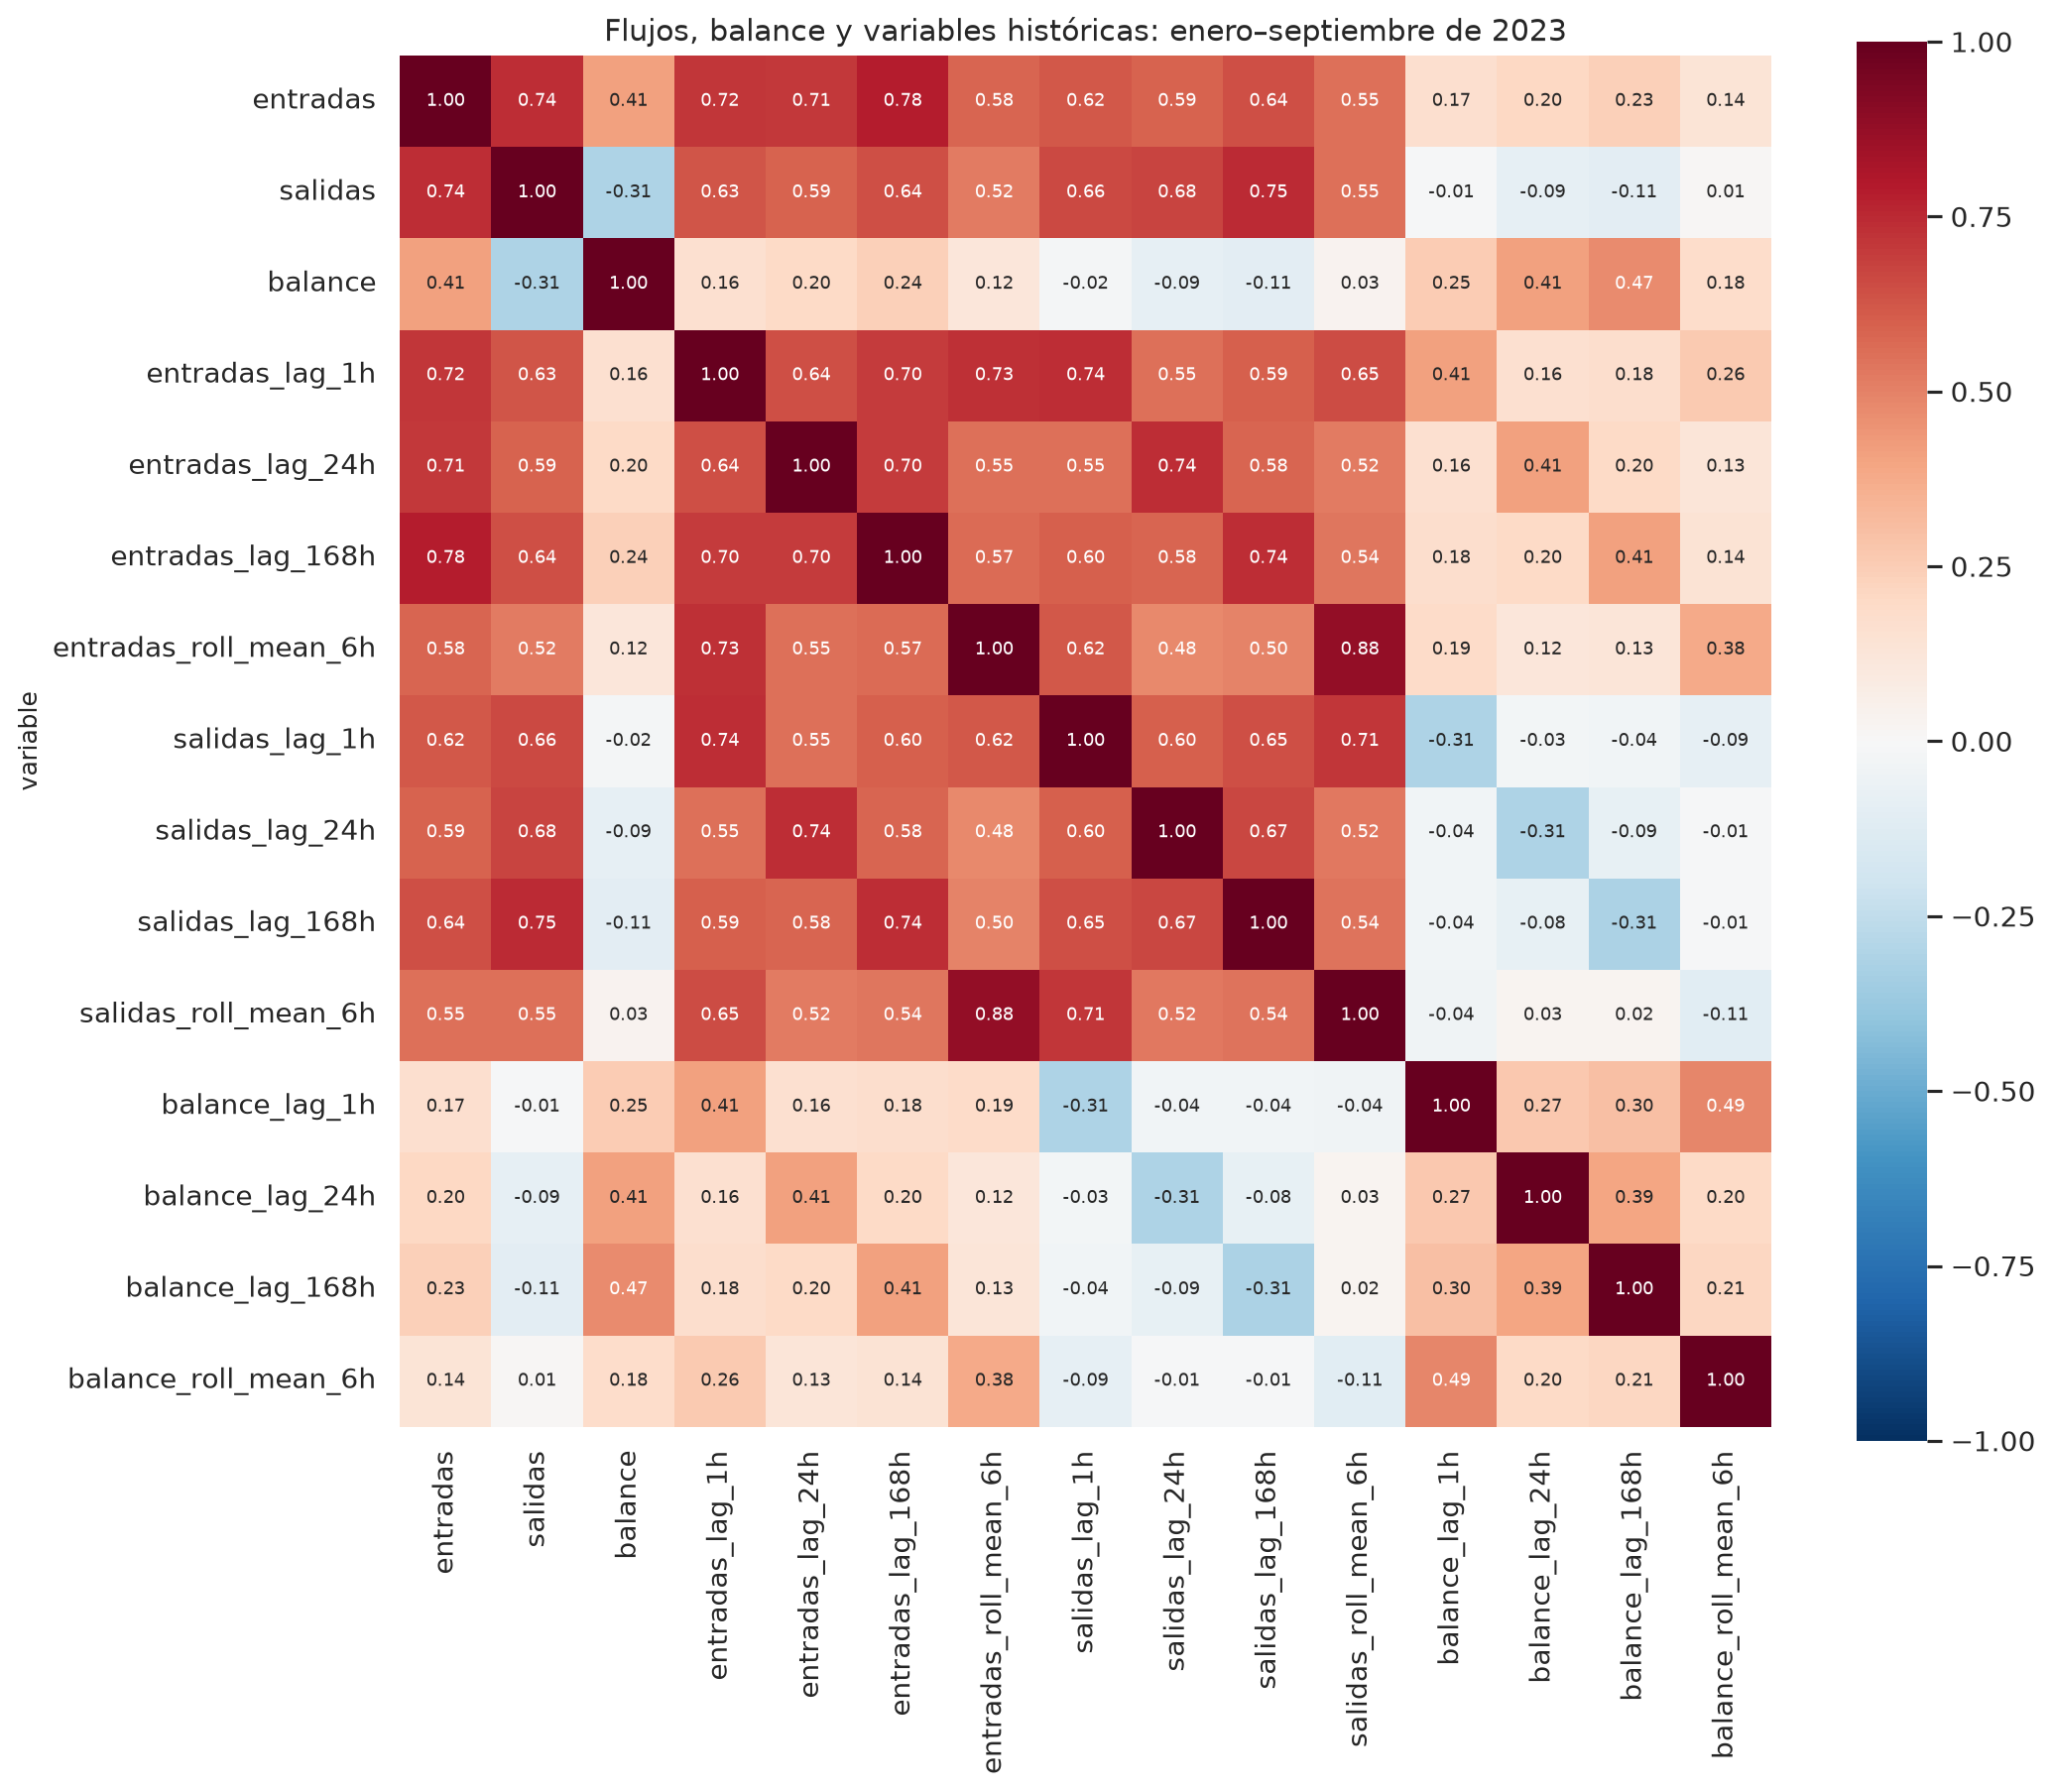

Filas empleadas en la correlación: 2291856


In [7]:
display(Image(filename=str(ROOT / 'reports/figures/05_matriz_correlacion_lags.png')))
print('Filas empleadas en la correlación:', resultado['metricas']['filas_correlacion_entrenamiento'])

## 7. Hallazgos, decisiones y límites

Las conclusiones siguientes se generan con las mismas tablas que las figuras. Los viajes con duración no positiva se excluyen; los atípicos por IQR y los viajes cortos o largos se diagnostican y conservan, porque una duración inusual no demuestra un error. El EDA completo de 2023 describe el histórico; no selecciona automáticamente variables ni acredita un pronóstico multihorizonte.

In [8]:
display(Markdown(Path(resultado['hallazgos']).read_text()))

Se analizaron 4,275,165 viajes conservados, 359 estaciones y 365 días. Los totales de entradas y salidas son iguales por construcción del conjunto, que exige que ambos extremos del viaje estén dentro de 2023.

El 48.54% de las combinaciones estación-hora no registra movimientos. Otro 8.85% tiene balance cero con entradas y salidas positivas. Un balance cero no implica ausencia de viajes.

Las tres horas con más salidas medias en lunes–viernes son 18:00, 8:00, 17:00. El promedio diario de salidas es 13,136 de lunes a viernes y 8,189 en fin de semana (37.7% menos). Se comparan promedios por día para evitar el efecto de tener distinto número de lunes, martes, etc.

El mes 3 tiene el mayor promedio diario de salidas (12,963); el mes 12, el menor (10,104). Son patrones descriptivos; no prueban causas como clima, cierres o cambios en la oferta.

La estación 51 presenta la mayor suma de desbalances horarios absolutos (76,910). Este indicador también depende del volumen de uso y no demuestra urgencia de rebalanceo: no tenemos inventario ni capacidad. Hay 572 combinaciones estación-mes sin movimientos; no se conocen sus fechas reales de apertura, cierre o fallos.

Las correlaciones se calcularon solo con enero–septiembre e incluyen las medias móviles reales *_roll_mean_6h. No prueban causalidad ni desempeño predictivo. La relación del balance con entradas y salidas es, en parte, consecuencia de su definición.

Se mantienen los conteos en sus unidades y la codificación cíclica de hora y día de semana. No se aplican escalado ni PCA: el modelo de árboles existente no requiere escalado y se prioriza interpretar las variables. La estación numérica y la bandera de hora pico son decisiones provisionales. Las variables históricas requieren que las horas anteriores ya se hayan observado; este EDA no acredita predicciones de varios pasos ni capacidad para anticipar bicicletas disponibles. No se reentrenaron modelos.


## Trazabilidad y fuentes

- Fuente: CSV de datos abiertos de MiBici contenidos en `mibici_raw_v1.tar.xz`, registrado como `raw_v1` en `manifests/mibici_original.json`.
- Las versiones actuales de los Parquet se identifican por SHA-256 y sus manifiestos en `manifests/`; el reporte de esta ejecución conserva los hashes de entrada.
- Las gráficas y tablas quedan en `reports/figures/` y `reports/eda/`, y como artefactos de MLflow.
- El conteo anterior de 3,908,646 viajes corresponde a una lectura que descartaba noviembre al no reconocer sus fechas. Esta versión exige lectura explícita y verifica el mes de cada archivo.
- Flujo inicial y EDA del equipo desarrollados por Leo; integración, revisión y ejecución local por Iván, con apoyo de OpenAI Codex para generación de código, depuración y documentación. La revisión y responsabilidad de la entrega corresponden al equipo.